EPSG:32606


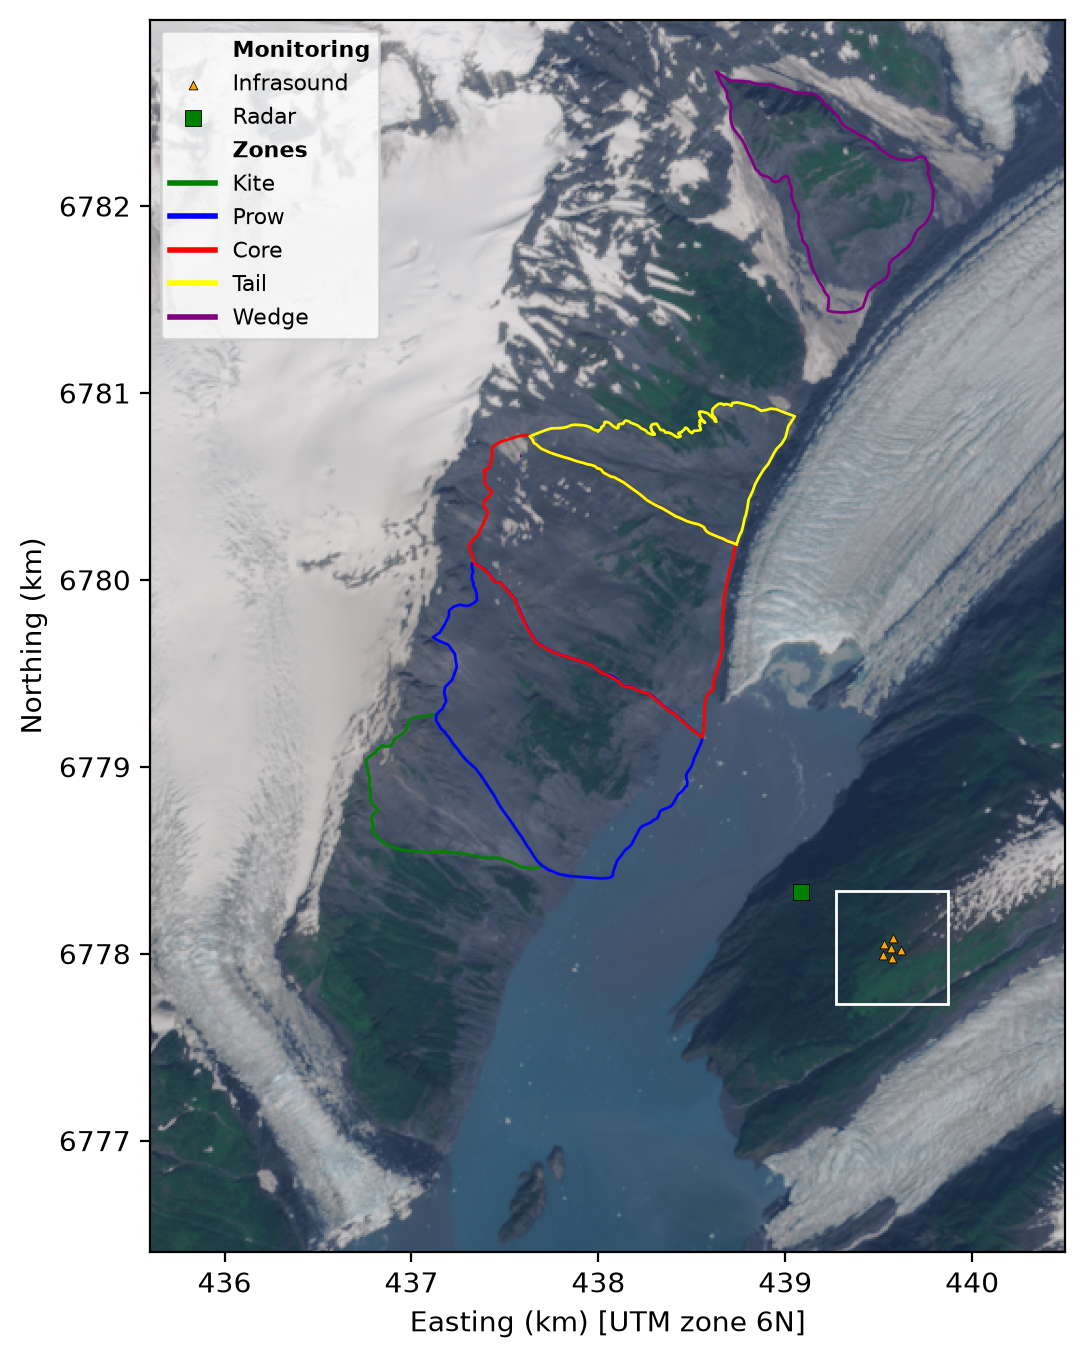

In [4]:
import rasterio
import numpy as np
import pyproj
from pyproj import Transformer
import matplotlib.pyplot as plt
import utm
import matplotlib.patches as mpatches
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.affinity import scale
import shapely.geometry as geom
import pandas as pd
from shapely.ops import unary_union
from shapely.geometry import MultiPolygon
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
from matplotlib.lines import Line2D
import xarray as xr
import matplotlib as mpl



# PLOT 1
#src/uafinfra2

xrange = (4.356e5, 4.405e5) #445000)
yrange = (6783000, 6776400)

def open_visual(img_file, xrange=None, yrange=None, x_shift=0, y_shift=0):
    """Load image, ensure UTM (EPSG:26906), optionally crop, return RGB numpy + UTM grids."""
    with rasterio.open(img_file) as src:
        data = src.read()       # (bands, y, x)
        transform = src.transform
        #print(transform)
        h, w = src.height, src.width
        img_crs = src.crs
        print(img_crs)

    rows, cols = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    X, Y = rasterio.transform.xy(transform, rows, cols, offset="center")
    X = np.array(X).reshape(h, w)
    Y = np.array(Y).reshape(h, w)


    # ensure correct crs
    target_crs = "EPSG:32606"
    if str(img_crs) != target_crs:
        print(img_crs)
        transformer = Transformer.from_crs(img_crs, target_crs, always_xy=True)
        x_utm, y_utm = transformer.transform(X, Y)
    else:
        x_utm, y_utm = X, Y

    # build RGB numpy array (y, x, 3)
    rgb = np.stack([data[i] for i in range(3)], axis=-1)

    if x_shift!=0:
        x_utm = x_utm + x_shift
    if y_shift!=0:
        y_utm = y_utm + y_shift

    # optional crop
    if xrange is not None and yrange is not None:
        x1d = x_utm[0, :]
        y1d = y_utm[:, 0]
        x_inds = np.where((x1d >= xrange[0]) & (x1d <= xrange[1]))[0]
        y_inds = np.where((y1d >= yrange[1]) & (y1d <= yrange[0]))[0]
        rgb = rgb[np.ix_(y_inds, x_inds, [0, 1, 2])]
        x_utm = x_utm[np.ix_(y_inds, x_inds)]
        y_utm = y_utm[np.ix_(y_inds, x_inds)]
    return rgb, x_utm/1000, y_utm/1000

def load_dem_basemap(dem_file, figsize=(10,10)):
    """open and clean dem, project to UTM"""
    dem = xr.open_dataarray(dem_file)
    # Clean DEM before going further
    dem = dem.squeeze(drop=True).rename('elevation')

    fig, ax = plt.subplots(figsize=figsize)
    hs = dem.copy()
    hs.data = mpl.colors.LightSource().hillshade(
        dem.data,
        dx=abs(dem.x.diff('x').mean().values),
        dy=abs(dem.y.diff('y').mean().values),
    )
    im = hs.plot.imshow(ax=ax, cmap='Greys_r', add_colorbar=False, add_labels=False)
    ax.set_aspect('equal')

    #ax.set_xlim(434000, 442000)
    #ax.set_ylim(6775000, 6783500)
    ax.set_xlim(436000, 441000)
    ax.set_ylim(6776000, 6782000)
    ax.set_xticklabels([f'{lbl/1000}' for lbl in ax.get_xticks()], size=12)
    ax.set_yticklabels([f'{lbl/1000}' for lbl in ax.get_yticks()], size=12)

    crs_wkt = dem.coords['spatial_ref'].attrs['crs_wkt'] # Extract the WKT of the CRS from the spatial_ref attribute
    utm_crs = pyproj.CRS.from_wkt(crs_wkt) # Create a CRS object from the WKT string
    #wgs84_proj = pyproj.CRS("EPSG:4326")  # WGS84 (latitude, longitude)
    #transformer = pyproj.Transformer.from_crs(wgs84_proj, utm_crs, always_xy=True) # Create the transformer for coordinate transformation
    
    utm_zone = utm_crs.utm_zone
    ax.set_ylabel(f'Northing (km)', size=14)
    ax.set_xlabel(f'Easting (km)  [UTM zone {utm_zone}]', size=14)
    

    return fig,ax, utm_zone#, transformer


#dem_file = "data/modified_dem_5m.tif"
#fig, ax, utm_zone = load_dem_basemap(dem_file)


#img_file = r"C:\Users\csaunders-shultz\Documents\data\sat_images\zoomed_2025-08-03-00_00_2025-08-03-23_59_Sentinel-2_L1C_Highlight_Optimized_Natural_Color.tiff"
#img_file = r"C:\Users\csaunders-shultz\Documents\data\sat_images\2025-08-03-00_00_2025-08-03-23_59_Sentinel-2_L1C_Highlight_Optimized_Natural_Color_UTM.tiff"
img_file = r"C:\Users\csaunders-shultz\OFFCLOUD\Landslides\data\newdata2026\2025-08-03-00_00_2025-08-03-23_59_Sentinel-2_L1C_Highlight_Optimized_Natural_Color_2.tiff"
rgb, x_rgb, y_rgb = open_visual(img_file, xrange, yrange)

#Initialize landsat 2 basemap
fig, ax = plt.subplots(figsize=(8,8), dpi=200)
extent = [x_rgb.min(), x_rgb.max(), y_rgb.min(), y_rgb.max()]
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
ax.imshow(rgb, extent=extent)
ax.set_xlabel("Easting (km) [UTM zone 6N]")
ax.set_ylabel("Northing (km)")


def plot_station_coords(ax, site_locations, marker='*', color='red', text=None, s=50, label=None, ec='k', lw=0.3):
    for name,ll in site_locations.items():
        x, y, zone_number, lat_band   = utm.from_latlon(ll[0], ll[1])
        x,y = x/1000, y/1000
        ax.scatter(x, y, marker=marker, s=s, color=color,label=label, ec=ec, lw=lw)
        if text is not None:
            ax.text(x+50, y, name)
        #return label



baei_stations = {'AV.BAEI.01.HDF': (61.132675, -148.1219), 'AV.BAEI.02.HDF': (61.132085, -148.12107), 'AV.BAEI.03.HDF': (61.13173, -148.121985), 
                 'AV.BAEI.04.HDF': (61.131875, -148.122915), 'AV.BAEI.05.HDF': (61.132405, -148.12281), 'AV.BAEI.06.HDF': (61.13218, -148.12206)}
plot_station_coords(ax, baei_stations, marker='^', color='orange', s=10, label='Infrasound')
bais_stations = {'BAIS.01': (61.11962, -148.158315), 'BAIS.02': (61.119775, -148.157485), 
 'BAIS.03': (61.11939, -148.1579), 'BAIS.04': (61.119575, -148.157775)}
#plot_station_coords(ax, bais_stations, marker='.', color='orange', s=50, ec='k')
bati = {'BATI':(61.14172, -148.175)}
#plot_station_coords(ax, bati, marker='.', color='orange', s=100)
radar = {'RADAR': (61.1348, -148.1311)}
plot_station_coords(ax, radar, marker='s', color='green', s=30, label="Radar") # Marker: Square

def plot_kinematic_elements():
    # path to the .shp
    #shp_path = r"C:\Users\csaunders-shultz\Documents\data\sat_images\Barry_Arm_GIS_MAP_Data\Shapefiles\Kinematic_Elements.shp"
    shp_path = r"C:\Users\csaunders-shultz\OFFCLOUD\Landslides\data\newdata2026\Barry_Arm_Data\Shapefiles\Kinematic_Elements.shp"
    # read
    gdf = gpd.read_file(shp_path)
    # gdf = gdf.iloc[0:4] #drop wedge
    #re order
    order = ['Kite', 'Prow', 'Core', 'Tail', 'Wedge']
    gdf['Name'] = pd.Categorical(gdf['Name'], categories=order, ordered=True)
    gdf = gdf.sort_values('Name')
    #scale to kms
    gdf['geometry'] = gdf['geometry'].apply(lambda g: scale(g, xfact=1/1000, yfact=1/1000, origin=(0,0)))
    # plot
    colors = ["lightgreen", "lightblue", "lightcoral", "yellow"]
    colors = ["lightcoral","lightcoral","lightcoral","lightcoral"]
    colors = ['green', 'blue', 'red', 'yellow', 'purple']
    gdf.plot(
        ax=ax,
        edgecolor=colors,
        alpha=1.0, lw=1,
        color="none"
    )
plot_kinematic_elements()

def plot_polygon(coords, ax, color='red'):
    # Draw the polygon
    utm_coords = [(x / 1000, y / 1000) for x, y in
              (utm.from_latlon(ll[0], ll[1])[:2] for ll in coords)]
    #print(utm_coords)
    polygon = geom.Polygon(utm_coords)  # Create polygon from UTM coordinates
    x, y = polygon.exterior.xy  # Get the x and y coordinates of the polygon
    #Plot the polygon on the basemap (in UTM coordinates)
    ax.plot(x, y, color=color, linewidth=2, alpha=1)
    return polygon #return the polygon object in utm coordinates
glacier_poly_ll = [(61.14357, -148.14055),
                   (61.147, -148.134),
                   (61.14750, -148.125),
                   (61.143, -148.123),
                   (61.14357, -148.14055)]
#gl_poly = plot_polygon(glacier_poly_ll, ax=ax, color='tab:brown')


#plot legend without duplicates:
# Kinematic element handles
monitor_title = [mpatches.Patch(facecolor='none', edgecolor='none', label='Monitoring')]
kin_title     = [mpatches.Patch(facecolor='none', edgecolor='none', label='Zones')]
handles1, labels1 = ax.get_legend_handles_labels()
unique = dict(zip(labels1, handles1))
handles1, labels1 = list(unique.values()), list(unique.keys())

kin_colors = ['green', 'blue', 'red', 'yellow', 'purple']
kin_labels = ['Kite', 'Prow', 'Core', 'Tail', 'Wedge']
handles2 = [
    Line2D([0], [0], color=c, linewidth=2, label=l)
    for c, l in zip(kin_colors, kin_labels)
]

all_handles = monitor_title + handles1 + kin_title + handles2
all_labels  = [h.get_label() for h in all_handles]

leg = ax.legend(handles=all_handles, labels=all_labels, fontsize=8, loc='upper left', ncols=1)
for text in leg.get_texts():
    if text.get_text() in ['Monitoring', 'Zones']:
        text.set_fontweight('bold')


map_crs = pyproj.CRS.from_epsg(32606)
station_transformer = Transformer.from_crs("EPSG:4326", map_crs, always_xy=True)
baei_names = list(baei_stations)
baei_lon = [baei_stations[name][1] for name in baei_names]
baei_lat = [baei_stations[name][0] for name in baei_names]
baei_map_x, baei_map_y = station_transformer.transform(baei_lon, baei_lat)
baei_map_x = np.asarray(baei_map_x)
baei_map_y = np.asarray(baei_map_y)

zoom_margin_m = 250
zoom_xmin = baei_map_x.min() - zoom_margin_m
zoom_xmax = baei_map_x.max() + zoom_margin_m
zoom_ymin = baei_map_y.min() - zoom_margin_m
zoom_ymax = baei_map_y.max() + zoom_margin_m
zoom_bounds_km = (zoom_xmin / 1000, zoom_ymin / 1000, (zoom_xmax - zoom_xmin) / 1000, (zoom_ymax - zoom_ymin) / 1000)
ax.add_patch(
    mpatches.Rectangle(
        (zoom_bounds_km[0], zoom_bounds_km[1]),
        zoom_bounds_km[2],
        zoom_bounds_km[3],
        fill=False,
        edgecolor="white",
        linewidth=1,
    )
)


#ax.set_title('Infrasound sensors, summer 2023', size=15)

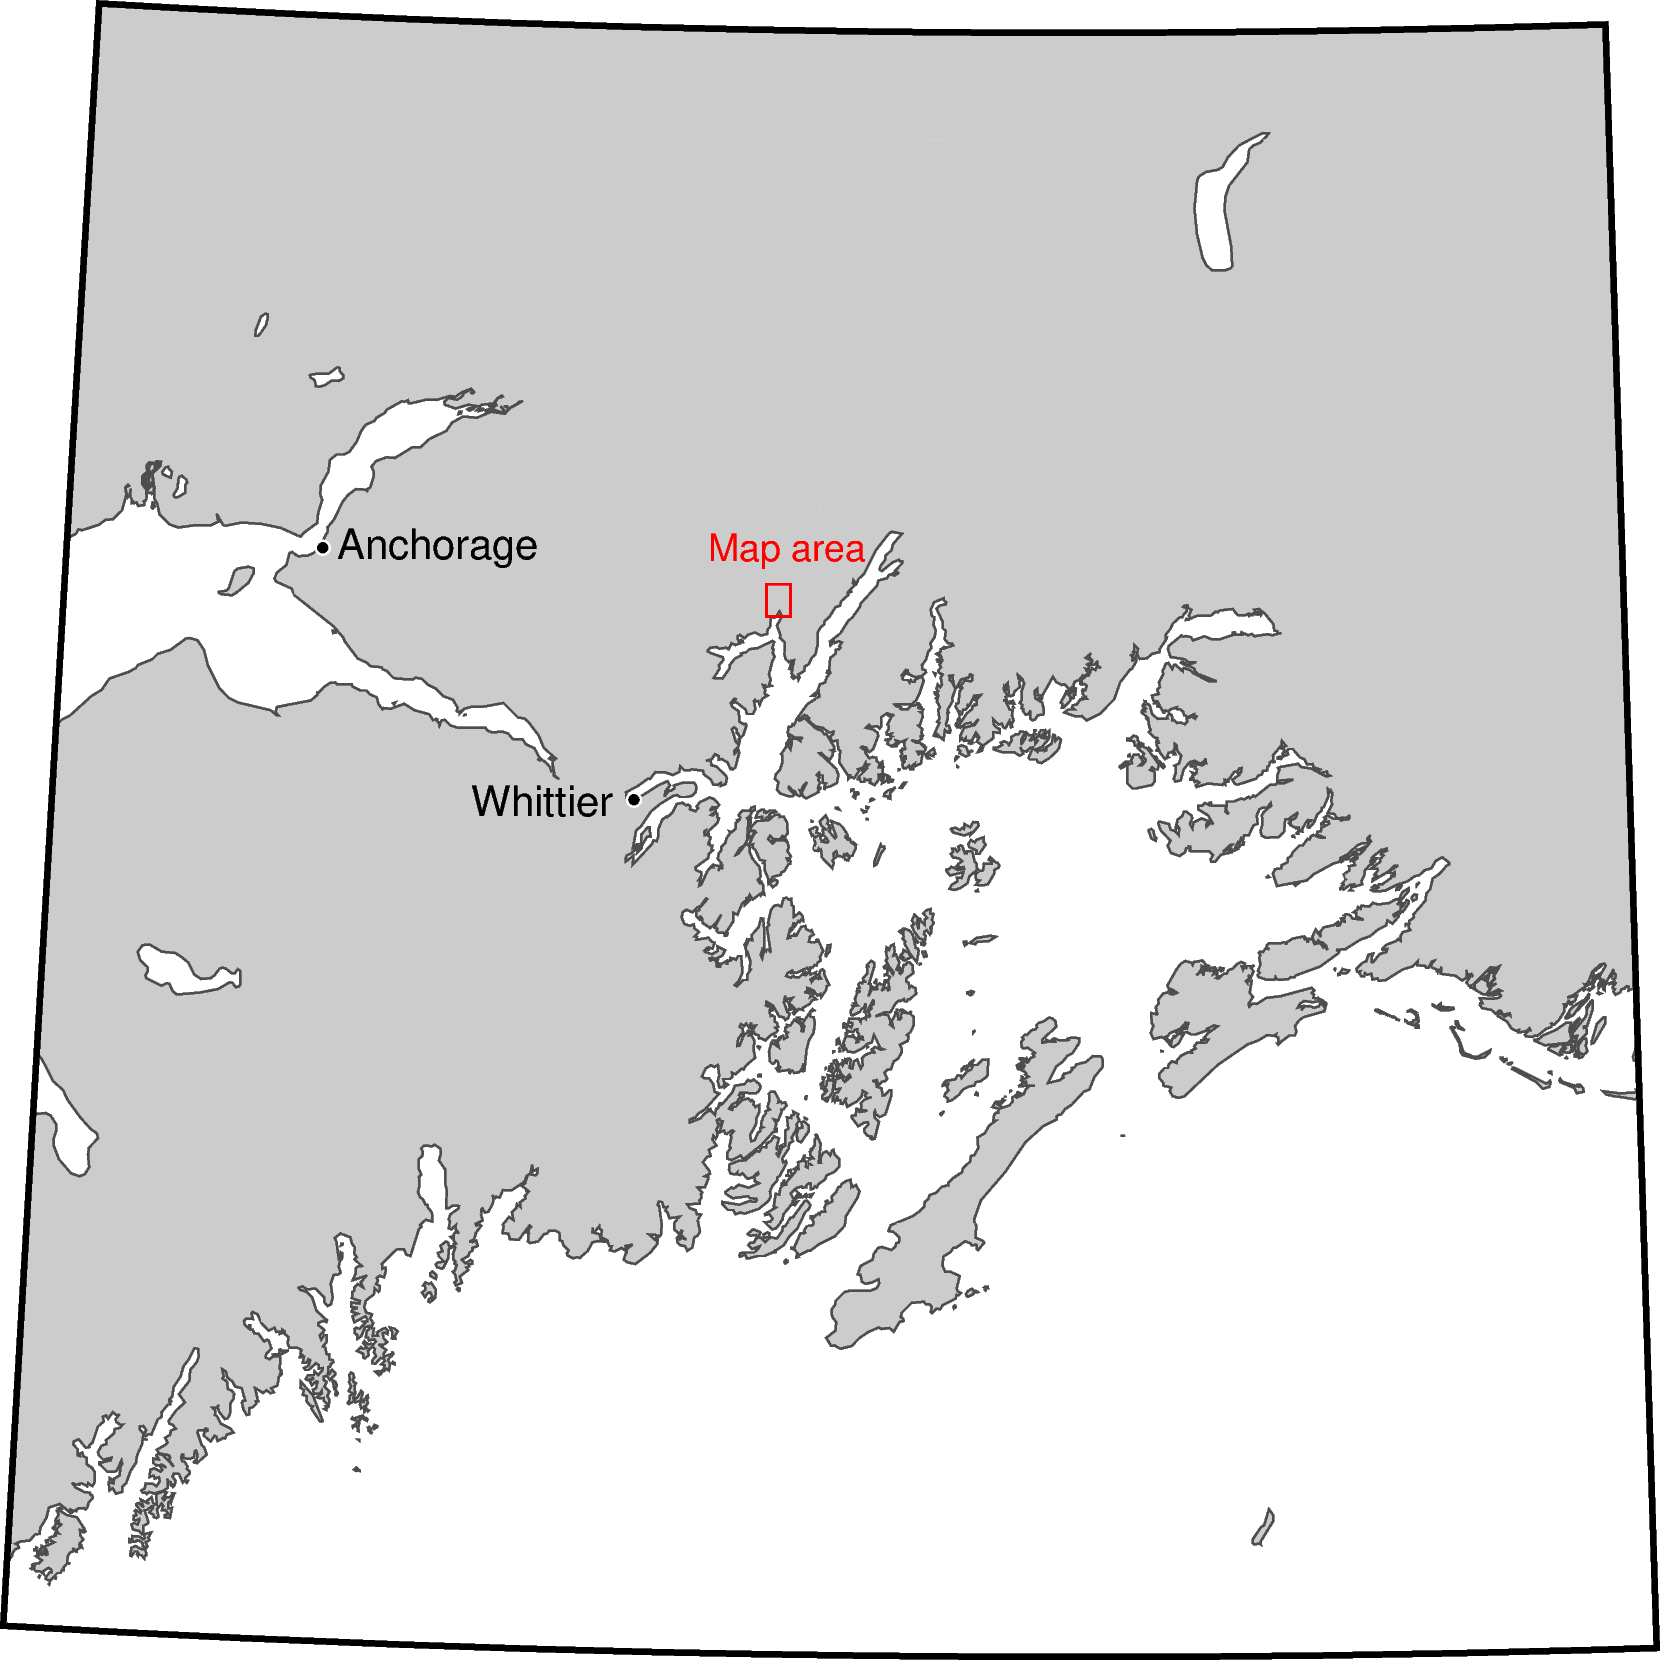

: 

In [ ]:
import pygmt


def plot_alaska_locator(image_extent_km, image_crs="EPSG:32606"):
    """Plot Prince William Sound coastlines in a square UTM region."""
    west, east, south, north = -150.8, -145.0, 59.2, 62.2
    geographic_to_utm = Transformer.from_crs("EPSG:4326", image_crs, always_xy=True)
    for _ in range(3):
        longitude_edges = np.linspace(west, east, 201)
        latitude_edges = np.linspace(south, north, 201)
        longitudes = np.concatenate((longitude_edges, longitude_edges, np.full(201, west), np.full(201, east)))
        latitudes = np.concatenate((np.full(201, south), np.full(201, north), latitude_edges, latitude_edges))
        projected_x, projected_y = geographic_to_utm.transform(longitudes, latitudes)
        projected_width, projected_height = np.ptp(projected_x), np.ptp(projected_y)
        center_lon = (west + east) / 2
        longitude_span = (east - west) * projected_height / projected_width
        west, east = center_lon - longitude_span / 2, center_lon + longitude_span / 2

    fig = pygmt.Figure()
    fig.coast(region=[west, east, south, north], projection="U6/14c", land="gray80", shorelines="0.5p,gray30", resolution="high", frame="WSne")

    map_to_lonlat = Transformer.from_crs(image_crs, "EPSG:4326", always_xy=True)
    x_min_km, x_max_km, y_min_km, y_max_km = image_extent_km
    box_x = np.array([x_min_km, x_max_km, x_max_km, x_min_km, x_min_km]) * 1000
    box_y = np.array([y_min_km, y_min_km, y_max_km, y_max_km, y_min_km]) * 1000
    box_lon, box_lat = map_to_lonlat.transform(box_x, box_y)
    fig.plot(x=box_lon, y=box_lat, pen="0.6p,red", close=True)

    fig.plot(x=-149.9003, y=61.2181, style="c0.12c", fill="black", pen="0.4p,white")
    fig.text(x=-149.9003, y=61.2181, text="Anchorage", font="10p,Helvetica,black", justify="LM", offset="0.12c/0.03c")
    fig.plot(x=-148.6833, y=60.7732, style="c0.12c", fill="black", pen="0.4p,white")
    fig.text(x=-149.35, y=60.75445, text="Whittier", font="10p,Helvetica,black", justify="LM", offset="0.12c/0.03c")

    map_center_x, map_center_y = (x_min_km + x_max_km) * 500, (y_min_km + y_max_km) * 500
    map_center_lon, map_center_lat = map_to_lonlat.transform(map_center_x, map_center_y)
    fig.text(x=map_center_lon, y=map_center_lat, text="Map area", font="9p,Helvetica,red", justify="LM", offset="-0.6c/0.45c")
    return fig


fig_alaska_locator = plot_alaska_locator(extent)
fig_alaska_locator.show(method="notebook", width=700)

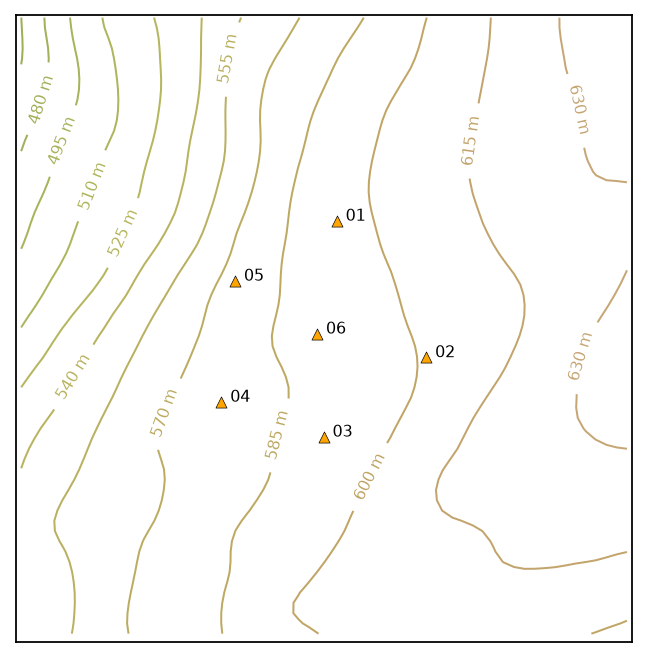

In [69]:
# Plot 2

dem_file = "data/modified_dem_5m.tif"
dem = xr.open_dataarray(dem_file).squeeze(drop=True).rename("elevation")
dem_crs = pyproj.CRS.from_wkt(dem.coords["spatial_ref"].attrs["crs_wkt"])
station_transformer = Transformer.from_crs("EPSG:4326", dem_crs, always_xy=True)

baei_names = list(baei_stations)
baei_lon = [baei_stations[name][1] for name in baei_names]
baei_lat = [baei_stations[name][0] for name in baei_names]
baei_x, baei_y = station_transformer.transform(baei_lon, baei_lat)
baei_x = np.asarray(baei_x)
baei_y = np.asarray(baei_y)

margin_m = 100
x_min, x_max = baei_x.min() - margin_m, baei_x.max() + margin_m
y_min, y_max = baei_y.min() - margin_m, baei_y.max() + margin_m
x_inds = np.flatnonzero((dem.x.values >= x_min) & (dem.x.values <= x_max))
y_inds = np.flatnonzero((dem.y.values >= y_min) & (dem.y.values <= y_max))
dem_baei = dem.isel(x=x_inds, y=y_inds)

fig_baei, ax = plt.subplots(figsize=(4, 4), dpi=160, constrained_layout=True)
fig_baei.patch.set_alpha(0)
contours = ax.contour(
    dem_baei.x.values / 1000,
    dem_baei.y.values / 1000,
    dem_baei.values,
    levels=15,
    cmap="gist_earth", vmin=-100, vmax=800,
    linewidths=0.9, zorder=1,
)
ax.clabel(contours, inline=True, fontsize=7, fmt="%d m")

ax.scatter(
    baei_x / 1000,
    baei_y / 1000,
    marker='^', color='orange', s=25, zorder=2, ec='k', lw=0.3
)
for name, x, y in zip(baei_names, baei_x, baei_y):
    ax.annotate(
        name.replace("AV.", "").replace(".HDF", "").replace("BAEI.", ""),
        (x / 1000, y / 1000),
        xytext=(4, 0),
        textcoords="offset points",
        fontsize=7, zorder=2
    )

ax.set_xlim(x_min / 1000, x_max / 1000)
ax.set_ylim(y_min / 1000, y_max / 1000)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Easting (km)")
ax.set_ylabel("Northing (km)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(axis="both", which="both", bottom=False, top=False, left=False, right=False)

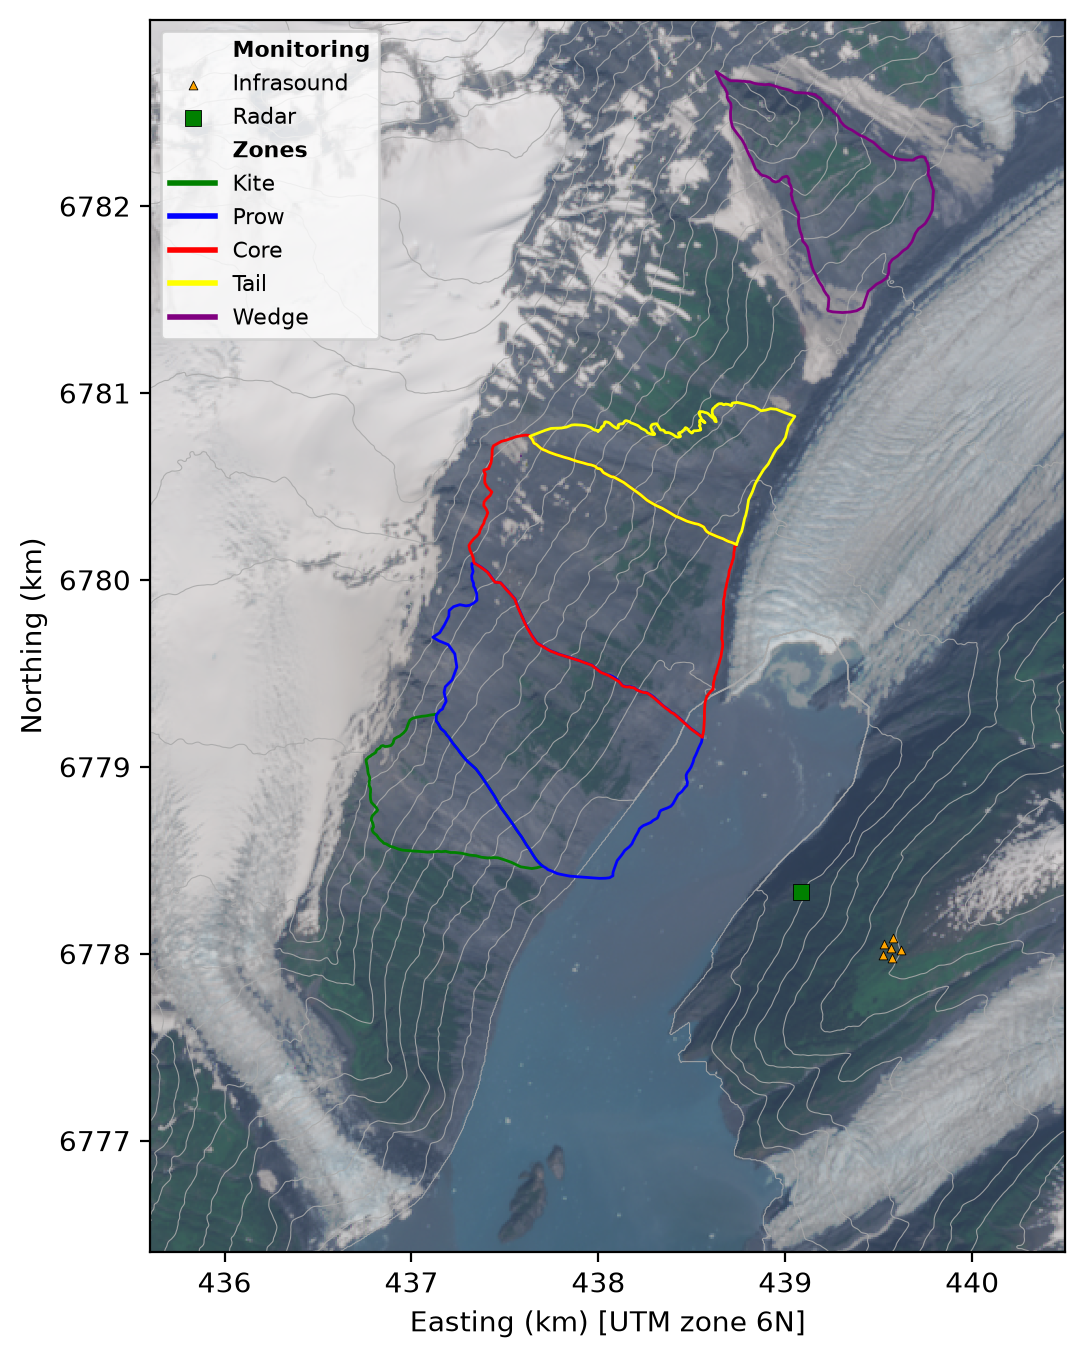

In [10]:
#PLOT 3: satellite imagery with contours
map_crs = pyproj.CRS.from_epsg(32606)

fig, ax = plt.subplots(figsize=(8, 8), dpi=200)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
extent = [x_rgb.min(), x_rgb.max(), y_rgb.min(), y_rgb.max()]
ax.imshow(rgb, extent=extent, alpha=0.9)

# Transform the DEM into the satellite image CRS and draw contours on the map.
dem = xr.open_dataarray("data/modified_dem_5m.tif").squeeze(drop=True).rename("elevation")
dem_crs = pyproj.CRS.from_wkt(dem.coords["spatial_ref"].attrs["crs_wkt"])
map_to_dem = Transformer.from_crs(map_crs, dem_crs, always_xy=True)
map_corners_x = np.array([extent[0], extent[0], extent[1], extent[1]]) * 1000
map_corners_y = np.array([extent[2], extent[3], extent[2], extent[3]]) * 1000
dem_corners_x, dem_corners_y = map_to_dem.transform(map_corners_x, map_corners_y)
dem_x_inds = np.flatnonzero((dem.x.values >= min(dem_corners_x)) & (dem.x.values <= max(dem_corners_x)))
dem_y_inds = np.flatnonzero((dem.y.values >= min(dem_corners_y)) & (dem.y.values <= max(dem_corners_y)))
dem_map = dem.isel(x=dem_x_inds, y=dem_y_inds)
elevation = np.asarray(dem_map.values, dtype=float)
elevation[~np.isfinite(elevation)] = np.nan
contour_min = np.ceil(np.nanmin(elevation) / 100) * 100
contour_max = np.floor(np.nanmax(elevation) / 100) * 100
contour_levels = np.arange(contour_min, contour_max + 100, 100)
dem_x_grid, dem_y_grid = np.meshgrid(dem_map.x.values, dem_map.y.values)
dem_to_map = Transformer.from_crs(dem_crs, map_crs, always_xy=True)
contour_x, contour_y = dem_to_map.transform(dem_x_grid, dem_y_grid)
ax.contour(contour_x / 1000, contour_y / 1000, elevation, levels=contour_levels, colors="darkgray", linewidths=0.4, alpha=0.9, zorder=0)

plot_station_coords(ax, baei_stations, marker='^', color='orange', s=10, label='Infrasound')
plot_station_coords(ax, radar, marker='s', color='green', s=30, label='Radar')
plot_kinematic_elements()

monitor_title = [mpatches.Patch(facecolor='none', edgecolor='none', label='Monitoring')]
kin_title = [mpatches.Patch(facecolor='none', edgecolor='none', label='Zones')]
handles1, labels1 = ax.get_legend_handles_labels()
unique = dict(zip(labels1, handles1))
handles1, labels1 = list(unique.values()), list(unique.keys())
kin_colors = ['green', 'blue', 'red', 'yellow', 'purple']
kin_labels = ['Kite', 'Prow', 'Core', 'Tail', 'Wedge']
handles2 = [Line2D([0], [0], color=color, linewidth=2, label=label) for color, label in zip(kin_colors, kin_labels)]
all_handles = monitor_title + handles1 + kin_title + handles2
leg = ax.legend(handles=all_handles, labels=[handle.get_label() for handle in all_handles], fontsize=8, loc='upper left')
for text in leg.get_texts():
    if text.get_text() in ['Monitoring', 'Zones']:
        text.set_fontweight('bold')

ax.set_aspect('equal')
ax.set_xlabel("Easting (km) [UTM zone 6N]")
ax.set_ylabel("Northing (km)")
plt.show()